In [35]:
import numpy as np
import pandas as pd
import random as random
import matplotlib.pyplot as plt
import math
import scipy
import scipy.stats as st

Distribuciones M1, M2, Comp. Lect., Ranking y NEM


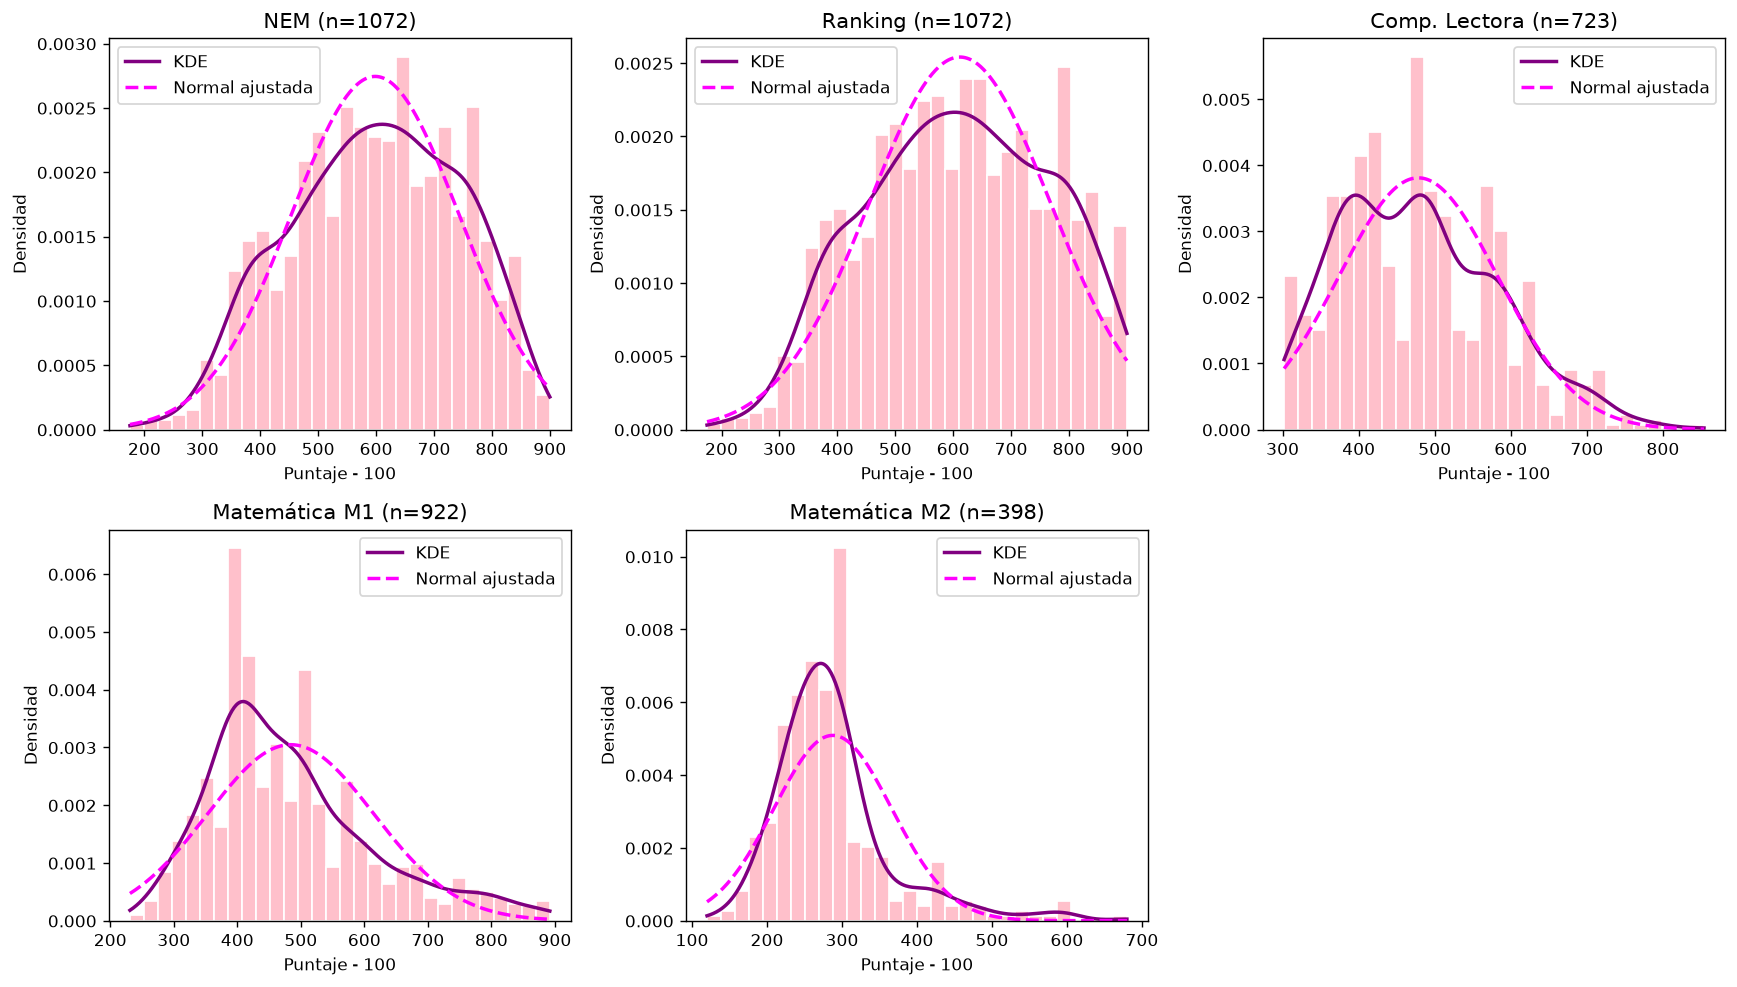

In [36]:
#Los datos ya están desplazados en 100 puntos menos, como la recomendación del enunciado.

df = pd.read_csv("../data/precessed/colegios_independencia_PAES2025_desplazados.csv")

cols = ["PTJE_NEM", "PTJE_RANKING", "CLEC_REG_ACTUAL",
        "MATE1_REG_ACTUAL", "MATE2_REG_ACTUAL"]
nombres = ["NEM", "Ranking", "Comp. Lectora", "Matemática M1", "Matemática M2"]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for ax, c, nombre in zip(axes, cols, nombres):
    x = df[c].dropna()
    grid = np.linspace(x.min(), x.max(), 400)

    ax.hist(x, bins=30, edgecolor="white", color="pink", density=True)

    # KDE (naranja)
    ax.plot(grid, st.gaussian_kde(x)(grid), color="purple", lw=2, label="KDE")

    # Normal ajustada (verde punteada)
    ax.plot(grid, st.norm.pdf(grid, loc=x.mean(), scale=x.std(ddof=1)),
            "--", color="fuchsia", lw=2, label="Normal ajustada")

    ax.set_title(f"{nombre} (n={len(x)})")
    ax.set_xlabel("Puntaje - 100")
    ax.set_ylabel("Densidad")
    ax.legend()

axes[-1].axis("off")
plt.tight_layout()
plt.savefig("../results/t2_p1_histogramas.png", dpi=150)
plt.show()

Están los histogramas de cada prueba, además de un KDE para ver la densidad estimada en cada intervalo y una normal ajustada a la media y varianza de los datos.

Definitivamente no tienen la misma distribucion, las de nem y ranking son muy achatadas y están hacia la derecha. El resto tiene sus peaks más hacia la izquierda, y luego una cola de baja densidad hacia la derecha. Podemos notar peaks marcados en las pruebas de matemáticas, mientras que en lenguaje vemos que se encuentran varios intervalos con una densidad alta.

Como ya fue mencionado, vemos que M1 y Competencia lectora se pueden asemejar a normales, sin embargo, competencia lectora tiene varios picos de densidad, escapandose un poco de esta distribución. 

Intervalos de Confianza <br>
Supondemos que MATE1_REG_ACTUAL son una M.A.S. $X_i\sim \text{Lognormal}(\mu, \sigma^2)$


Grafiquemos el histograma de las $Z_i=\ln (X_i)$, $z_i=\ln (x_i)$.

<positron-console-cell-38>:3: SyntaxWarning: invalid escape sequence '\l'


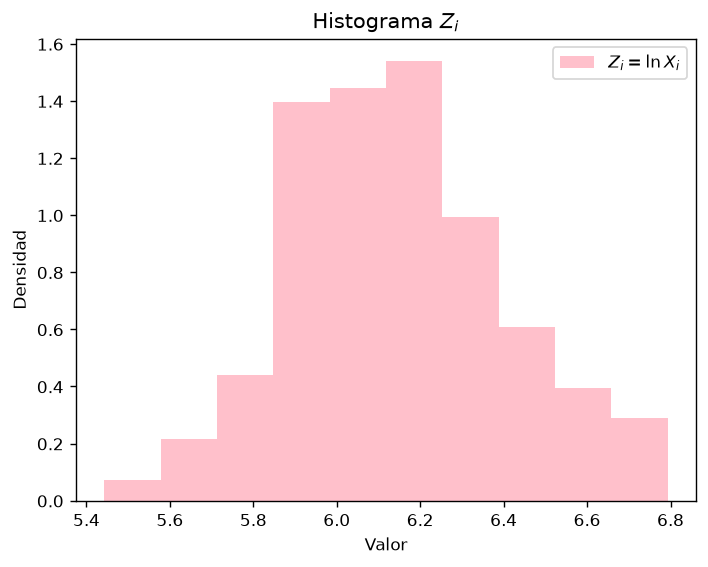

In [37]:
df = pd.read_csv("../data/precessed/colegios_independencia_PAES2025_desplazados.csv")

plt.hist( np.log(df["MATE1_REG_ACTUAL"]),color="pink",label="$Z_i= \ln X_i$",density=True)
plt.xlabel("Valor")
plt.ylabel("Densidad")
plt.title("Histograma $Z_i$")
plt.legend()
plt.savefig("../results/t2_p1_histograma_Z_i.png")
plt.show()

<positron-console-cell-39>:4: SyntaxWarning: invalid escape sequence '\l'


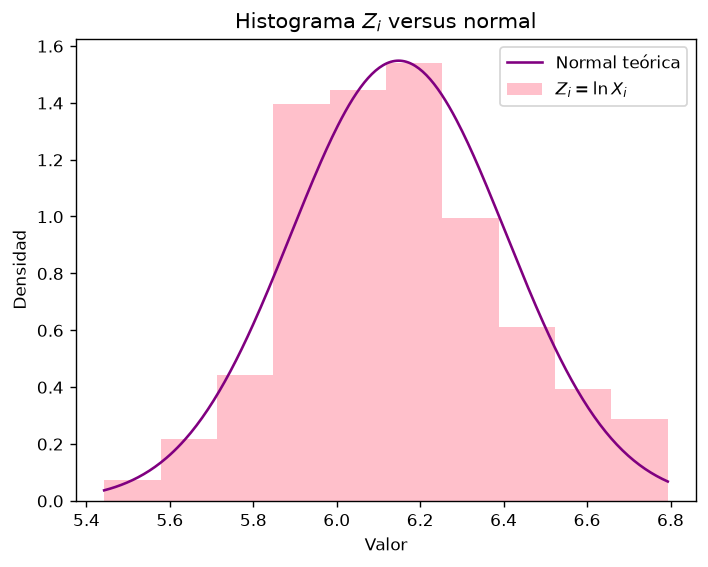

In [38]:
x = np.linspace(np.log(df["MATE1_REG_ACTUAL"]).min(), np.log(df["MATE1_REG_ACTUAL"]).max(), 300)  

plt.plot(x, scipy.stats.norm.pdf(x, loc=np.log(df["MATE1_REG_ACTUAL"]).mean() , scale=np.log(df["MATE1_REG_ACTUAL"]).std()), color="purple", label="Normal teórica") 
plt.hist( np.log(df["MATE1_REG_ACTUAL"]),color="pink", density=True, label="$Z_i= \ln X_i$") 
plt.xlabel("Valor") 
plt.ylabel("Densidad") 
plt.title("Histograma $Z_i$ versus normal") 
plt.legend() 
plt.savefig("../results/t2_p1_histograma_Z_i_vs_normal.png") 
plt.show()

Nos piden discutir propiedades del estimador propuesto, ver sesgo, consistencia, normalidad asintotica

Tenemos el estimador $\hat{\theta}_n = \exp(\bar{Z}+\frac{S^2_Z}{2})$.

In [39]:
#definimos las funciones pedidas


#método 1
def asintotico(x, alpha):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)] #filtramos los datos vacíos
    z = np.log(x)
    n = len(z)
    zbar = z.mean()
    s2 = z.var(ddof=1)
    Tn = np.exp(zbar + s2 / 2)
    Vn = Tn**2 * (s2 + s2**2 / 2)
    cuantil = st.norm.ppf(1 - alpha / 2)
    err = cuantil * np.sqrt(Vn / n)
    return (Tn - err, Tn + err)

#método 2
def cox(x, alpha):
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]
    z = np.log(x); n = len(z)
    zbar, s2 = z.mean(), z.var(ddof=1)
    scap = np.sqrt(s2/n + s2**2/(2*(n-1)))
    cuantil = st.norm.ppf(1 - alpha/2)
    a = zbar + s2/2
    return (np.exp(a - cuantil*scap), np.exp(a + cuantil*scap))


#método 3
def gci(x, alpha, m=1000, semilla=223):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    z = np.log(x)
    n = len(z)

    # Paso 1: estadísticos de los datos
    zbar = z.mean()
    s2 = z.var(ddof=1)
    s = np.sqrt(s2)

    # Paso 2 y 3: simular m veces
    rng = np.random.default_rng(semilla)
    epsilon = rng.standard_normal(m)              
    U2 = rng.chisquare(df=n - 1, size=m)       
    U = np.sqrt(U2)

    T = np.exp(zbar
               - epsilon / (U / np.sqrt(n - 1)) * (s / np.sqrt(n))
               + s2 / (2 * U2 / (n - 1)))

    # Paso 4: ordenar y tomar los cuantiles alpha/2 y 1-alpha/2
    T = np.sort(T)
    inf = T[int(np.floor(m * alpha / 2))]
    sup = T[min(int(np.ceil(m * (1 - alpha / 2))) - 1, m - 1)]
    return (inf, sup)

Falta comentar cosas sobre estos metodos y derivaciones matematicas, pero van en el informe

In [ ]:
df = pd.read_csv("../data/precessed/colegios_independencia_PAES2025_desplazados.csv")
m1 = df["MATE1_REG_ACTUAL"].dropna()

metodos = {"Asintótico": asintotico, "Cox": cox, "GCI": gci}

def tabla_ic(x, alpha): #construimos diccionarios gaurdando los datos de usar cada metodo
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    filas = []
    for nombre, f in metodos.items():
        inf, sup = f(x, alpha)
        filas.append({"método": nombre, "alpha": alpha, "n": len(x),
                      "inf": inf, "sup": sup, "largo": sup - inf})
    return pd.DataFrame(filas)


#Variar alpha
t_todos = pd.concat([tabla_ic(m1, alpha) for alpha in [0.10, 0.05, 0.01]], ignore_index=True)
print(t_todos.round(2))
t_todos.to_csv("../results/t2_p1_ic_todos.csv", index=False)

#alpha = 0.05, estudiaremos grupos distintos (tipo de establecimiento, colegios, modalidad)
grupos = {}
for k, g in df.groupby("TIPO_ESTABLECIMIENTO"): grupos[f"Tipo: {k}"] = g["MATE1_REG_ACTUAL"]
for k, g in df.groupby("MODALIDAD"):            grupos[f"Modalidad: {k}"] = g["MATE1_REG_ACTUAL"]
cnt = df.groupby("NOMBRE_COLEGIO")["MATE1_REG_ACTUAL"].count()
for k in cnt[cnt >= 5].index:                 
    grupos[f"Colegio: {k}"] = df.loc[df.NOMBRE_COLEGIO == k, "MATE1_REG_ACTUAL"]

t_grupos = pd.concat([tabla_ic(x.dropna(), 0.05).assign(grupo=nombre)
                      for nombre, x in grupos.items() if x.notna().sum() >= 5],
                     ignore_index=True)
print(t_grupos.round(1).to_string())
t_grupos.to_csv("../results/t2_p1_ic_grupos.csv", index=False)



       método  alpha    n     inf     sup  largo
0  Asintótico   0.10  922  476.82  490.55  13.73
1         Cox   0.10  922  476.87  490.60  13.73
2         GCI   0.10  922  477.06  490.66  13.60
3  Asintótico   0.05  922  475.51  491.86  16.36
4         Cox   0.05  922  475.58  491.93  16.36
5         GCI   0.05  922  475.95  491.66  15.72
6  Asintótico   0.01  922  472.94  494.43  21.50
7         Cox   0.01  922  473.05  494.56  21.50
8         GCI   0.01  922  473.88  494.50  20.61
        método  alpha    n    inf    sup  largo                                                            grupo
0   Asintótico    0.0  227  440.2  467.4   27.1                                                  Tipo: Municipal
1          Cox    0.0  227  440.4  467.6   27.1                                                  Tipo: Municipal
2          GCI    0.0  227  441.2  467.3   26.1                                                  Tipo: Municipal
3   Asintótico    0.0   81  514.2  582.4   68.2           

Hay que comentar, va en el informe sgn yo